# Stage B: Sessionization & Feature Engineering

Groups each MAC's raw RSSI readings, per sensor, into continuous "visit"
sessions (gap-based splitting) and extracts per-session features.

**Rebuilt** after Stage A was corrected to use the full second-resolution
Sensor A log (`sensor_A_deduped.parquet`, 638,254 rows, vs. the old
undercounted 347,148). The 60s gap threshold was re-verified against the
corrected data (99.9% of gaps <=60s) and still holds.

Design doc: `docs/specs/2026-07-29-stage-b-sessionization-design.md`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "../DATA"
GAP_THRESHOLD_S = 60


## 1. Load Sensor A (Stage A output)

In [2]:
a_raw = pd.read_parquet(f"{DATA_DIR}/sensor_A_deduped.parquet")
a = a_raw[["MAC", "RSSI", "timestamp"]].rename(columns={"timestamp": "time"})
a["sensor"] = "A"

print(f"Sensor A rows: {len(a)}, unique MACs: {a['MAC'].nunique()}")


Sensor A rows: 641804, unique MACs: 14625


## 2. Load & dedup Sensor B

Same duplicate-export issue as Sensor A: several source files are
cumulative re-exports of the same log. Dedup on `(MAC, RSSI, timestamp)`
globally, same method as Stage A. No time interpolation needed here since
Sensor B already logs second resolution.


In [3]:
b1 = pd.read_excel(f"{DATA_DIR}/combined_file_sensor_B_part_1.xlsx")
b2 = pd.read_excel(f"{DATA_DIR}/combined_file_sensor_B_part_2.xlsx")
b_raw = pd.concat([b1, b2], ignore_index=True)

print(f"Sensor B raw rows: {len(b_raw)}")

b_dedup = b_raw.drop_duplicates(subset=["MAC", "RSSI", "timestamp"], keep="first").reset_index(drop=True)
print(f"Sensor B rows after dedup: {len(b_dedup)} (removed {len(b_raw) - len(b_dedup)})")

b = b_dedup[["MAC", "RSSI", "timestamp"]].rename(columns={"timestamp": "time"})
b["sensor"] = "B"
print(f"Sensor B unique MACs: {b['MAC'].nunique()}")


Sensor B raw rows: 1217216
Sensor B rows after dedup: 815093 (removed 402123)
Sensor B unique MACs: 18781


## 3. Sessionize

Per sensor: sort by `(MAC, time)`. A new session starts whenever the gap
since the previous reading of the same MAC exceeds `GAP_THRESHOLD_S`
(60s), or for the first reading of each MAC.


In [4]:
def assign_session_ids(df, gap_threshold_s=GAP_THRESHOLD_S):
    """Sort by (MAC, time) and assign a session id per continuous visit."""
    df = df.sort_values(["MAC", "time"]).reset_index(drop=True)
    gap = df.groupby("MAC")["time"].diff().dt.total_seconds()
    new_session = gap.isna() | (gap > gap_threshold_s)
    df["session_id"] = new_session.cumsum()
    return df

a_sessioned = assign_session_ids(a)
b_sessioned = assign_session_ids(b)

print(f"Sensor A: {len(a_sessioned)} readings -> {a_sessioned['session_id'].nunique()} sessions")
print(f"Sensor B: {len(b_sessioned)} readings -> {b_sessioned['session_id'].nunique()} sessions")


Sensor A: 641804 readings -> 15267 sessions
Sensor B: 815093 readings -> 19359 sessions


## 4. Extract per-session features

`rssi_trend` is the least-squares slope of RSSI vs. seconds-since-session-
start, computed via closed-form sums (vectorized, no per-group Python
loop). For sessions with a single reading, `x` is constant (0), the slope
denominator is 0, and `rssi_trend` naturally comes out `NaN` -- no special
case needed.


In [5]:
def extract_session_features(df):
    df = df.copy()
    df["x"] = (df["time"] - df.groupby("session_id")["time"].transform("min")).dt.total_seconds()
    df["xy"] = df["x"] * df["RSSI"]
    df["x2"] = df["x"] ** 2

    sessions = df.groupby("session_id").agg(
        sensor=("sensor", "first"),
        MAC=("MAC", "first"),
        start_time=("time", "min"),
        end_time=("time", "max"),
        n_readings=("time", "count"),
        mean_rssi=("RSSI", "mean"),
        sum_x=("x", "sum"),
        sum_xy=("xy", "sum"),
        sum_x2=("x2", "sum"),
    ).reset_index()

    sessions["duration_s"] = (sessions["end_time"] - sessions["start_time"]).dt.total_seconds()

    n = sessions["n_readings"]
    sum_x, sum_xy, sum_x2 = sessions["sum_x"], sessions["sum_xy"], sessions["sum_x2"]
    sum_y = sessions["mean_rssi"] * n
    denom = n * sum_x2 - sum_x ** 2
    sessions["rssi_trend"] = np.where(denom != 0, (n * sum_xy - sum_x * sum_y) / denom, np.nan)

    return sessions[["sensor", "MAC", "session_id", "start_time", "end_time",
                      "duration_s", "n_readings", "mean_rssi", "rssi_trend"]]

sessions_a = extract_session_features(a_sessioned)
sessions_b = extract_session_features(b_sessioned)

sessions_a.head()


,sensor,MAC,session_id,start_time,end_time,duration_s,n_readings,mean_rssi,rssi_trend
0,A,00:01:a5:f1:dc:c0,1,2026-05-19 11:28:31,2026-05-19 11:28:55,24.0,14,-91.857143,-0.091713
1,A,00:05:12:18:96:8a,2,2026-05-23 11:57:46,2026-05-23 11:58:11,25.0,15,-97.066667,0.102561
2,A,00:09:b2:fb:f4:36,3,2026-05-19 14:06:37,2026-05-19 14:07:55,78.0,47,-87.978723,-0.011603
3,A,00:0d:40:9e:7c:59,4,2026-05-24 10:30:39,2026-05-24 10:30:53,14.0,4,-93.250000,-0.552239
4,A,00:0d:5f:3a:4a:fb,5,2026-02-26 13:41:28,2026-02-26 13:42:05,37.0,8,-96.125000,-0.060985


## 5. Validation / sanity checks

In [6]:
# Sum of n_readings must equal the deduped input row count, per sensor
assert sessions_a["n_readings"].sum() == len(a), "Sensor A: reading count mismatch"
assert sessions_b["n_readings"].sum() == len(b), "Sensor B: reading count mismatch"
print("n_readings sum check passed for both sensors")

# duration_s must match end_time - start_time exactly
assert ((sessions_a["end_time"] - sessions_a["start_time"]).dt.total_seconds() == sessions_a["duration_s"]).all()
assert ((sessions_b["end_time"] - sessions_b["start_time"]).dt.total_seconds() == sessions_b["duration_s"]).all()
print("duration_s consistency check passed for both sensors")


n_readings sum check passed for both sensors
duration_s consistency check passed for both sensors


In [7]:
# Totals report
for label, sessions in [("A", sessions_a), ("B", sessions_b)]:
    single = (sessions["n_readings"] == 1).sum()
    multi = (sessions["n_readings"] > 1).sum()
    print(f"Sensor {label}: {len(sessions)} sessions total | "
          f"{single} single-reading (trend=NaN) | {multi} multi-reading")


Sensor A: 15267 sessions total | 649 single-reading (trend=NaN) | 14618 multi-reading
Sensor B: 19359 sessions total | 801 single-reading (trend=NaN) | 18558 multi-reading


In [8]:
# Spot-check: a MAC with multiple sessions on Sensor A
mac_session_counts = sessions_a.groupby("MAC")["session_id"].nunique().sort_values(ascending=False)
example_mac = mac_session_counts.index[0]
print(f"MAC {example_mac} has {mac_session_counts.iloc[0]} sessions on Sensor A")
sessions_a[sessions_a["MAC"] == example_mac][
    ["session_id", "start_time", "end_time", "duration_s", "n_readings", "mean_rssi", "rssi_trend"]
]


MAC d8:37:3b:96:d9:3a has 8 sessions on Sensor A


,session_id,start_time,end_time,duration_s,n_readings,mean_rssi,rssi_trend
12649,12650,2026-05-02 12:38:37,2026-05-02 12:53:26,889.0,798,-46.110276,0.011782
12650,12651,2026-05-02 13:24:08,2026-05-02 13:37:12,784.0,728,-88.885989,0.006615
12651,12652,2026-05-03 10:38:35,2026-05-03 10:39:42,67.0,40,-64.500000,0.035161
12652,12653,2026-05-16 07:51:06,2026-05-16 07:51:25,19.0,11,-53.909091,0.000000
12653,12654,2026-05-16 07:57:16,2026-05-16 07:58:20,64.0,56,-85.857143,-0.053334
12654,12655,2026-05-19 08:49:19,2026-05-19 09:00:29,670.0,575,-51.193043,-0.072415
12655,12656,2026-05-27 09:58:44,2026-05-27 09:59:10,26.0,14,-61.642857,0.110223
12656,12657,2026-05-27 10:05:23,2026-05-27 10:07:46,143.0,21,-98.190476,0.024905


In [9]:
# Spot-check: a MAC with one long multi-reading session
long_session = sessions_a.sort_values("n_readings", ascending=False).iloc[0]
print("Longest Sensor A session by reading count:")
long_session


Longest Sensor A session by reading count:


sensor                          A
MAC             ec:7d:d6:fc:3a:37
session_id                  14003
start_time    2026-05-25 11:03:57
end_time      2026-05-25 11:27:45
duration_s                 1428.0
n_readings                   1123
mean_rssi              -85.128228
rssi_trend               0.003581
Name: 14002, dtype: object

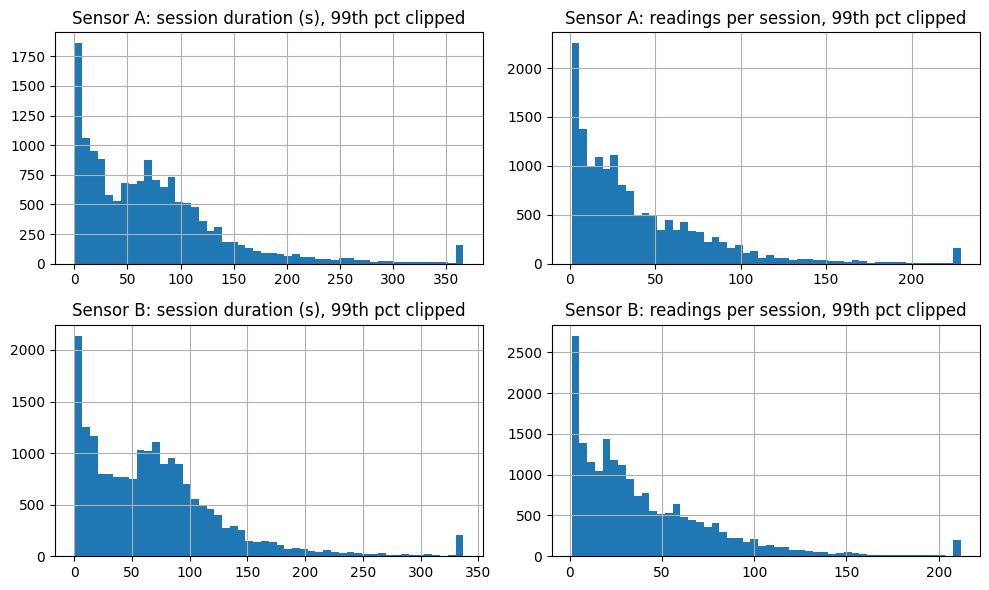

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

sessions_a["duration_s"].clip(upper=sessions_a["duration_s"].quantile(0.99)).hist(bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Sensor A: session duration (s), 99th pct clipped")

sessions_a["n_readings"].clip(upper=sessions_a["n_readings"].quantile(0.99)).hist(bins=50, ax=axes[0, 1])
axes[0, 1].set_title("Sensor A: readings per session, 99th pct clipped")

sessions_b["duration_s"].clip(upper=sessions_b["duration_s"].quantile(0.99)).hist(bins=50, ax=axes[1, 0])
axes[1, 0].set_title("Sensor B: session duration (s), 99th pct clipped")

sessions_b["n_readings"].clip(upper=sessions_b["n_readings"].quantile(0.99)).hist(bins=50, ax=axes[1, 1])
axes[1, 1].set_title("Sensor B: readings per session, 99th pct clipped")

plt.tight_layout()
plt.show()


## 6. Save outputs

In [11]:
sessions_a.to_csv(f"{DATA_DIR}/sessions_sensor_A.csv", index=False)
sessions_a.to_parquet(f"{DATA_DIR}/sessions_sensor_A.parquet", index=False)

sessions_b.to_csv(f"{DATA_DIR}/sessions_sensor_B.csv", index=False)
sessions_b.to_parquet(f"{DATA_DIR}/sessions_sensor_B.parquet", index=False)

print(f"wrote {len(sessions_a)} Sensor A sessions and {len(sessions_b)} Sensor B sessions")


wrote 15267 Sensor A sessions and 19359 Sensor B sessions
